# Chapter 13 · Project: the same twin in Emilia-Romagna (2021–22)
2D · first run about 50 min (`python tools/italy_runs.py`), then cached · *Rain twin, part 7*

A third network, and a third kind of sensor mix. Gothenburg had many links and a weak radar;
New York had few links and good stations. Emilia-Romagna, in northern Italy, has a region-wide
rain-gauge network, a sparse link network spread across it, and a radar that reads high:

| letter | sensor | what it sees | count |
|---|---|---|---|
| **L** | commercial microwave links (OpenRainER), FieldSense RNN retrieval | path-averaged rain | about 130 per storm |
| **P** | regional rain gauges (ARPAE), four of FieldSense's five folds | rain in a bucket | about 250 |
| **R** | the regional radar composite | rain rate on 2 km cells | observed every 6 km |
| | the fifth fold of gauges | **never assimilated**: it only scores | about 60 |

The data are FieldSense's inputs for its 10 Emilia-Romagna study storms (`projects/maps/multisensor`),
read by `raintwin.openrainer`. Two things differ from Chapters 10 and 12, and both come from the data:

* **Everything is hourly.** The twin steps one hour at a time (`Storm.step_h = 1`). Its noise is
  scaled by the step, so no setting changes.
* **The region is large**: 270 × 140 km on 2 km cells, six times as many cells as Gothenburg's
  grid. Observing the radar every 4 km, as in Gothenburg, makes the full twin take 9 s per hour of
  data, so it observes the radar every 6 km (`radar_thin=3`). Section 5 measures what this costs.

Every other setting is the one from Chapter 10.

**Scoring.** FieldSense scores its maps here by 5-fold cross-validation over the gauges: a map
that uses gauges is made without one fold and read at that fold. The twin does the same, so every
mix with P runs five times per storm. The score is hourly NRMSE (RMSE over the mean gauge rain)
on exactly the 97 345 gauge-hours FieldSense ranks its maps on.

**Questions**
1. With a dense gauge network, what does the twin add, and what do the links add?
2. The radar reads about 50 % high. Can the twin learn that, and does it then come close to
   FieldSense's best map, kriging with external drift of the radar on the gauges (KED)?

In [1]:
import sys; sys.path.insert(0, "..")
from pathlib import Path
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dtwin import viz
from raintwin import openrainer, system
viz.set_style()

CACHE = Path("../cache/ch13")
EVENTS = [e for e, _, _ in openrainer.events()]
MIXES = ["L", "R", "LR", "P", "LP", "LPR", "E-L", "E-LP", "P+", "LPR+", "R-4km"]
FIG_EVENT = "20220817T10"
missing = [m for m in MIXES for e in EVENTS if not list(CACHE.glob(f"{m}_{e}_f*.npz"))]
assert not missing, "run python tools/italy_runs.py first"

s = openrainer.Storm(FIG_EVENT)
print(f"{s.y.size} x {s.x.size} cells of {s.dx:.0f} km, {len(s.link_id)} links in this storm, "
      f"{s.gauges['inside'].sum()} gauges inside the grid")
print("gauges per fold:", np.bincount(s.fold[s.gauges["inside"]]))

69 x 136 cells of 2 km, 130 links in this storm, 301 gauges inside the grid
gauges per fold: [63 63 59 54 62]


## 1. The network

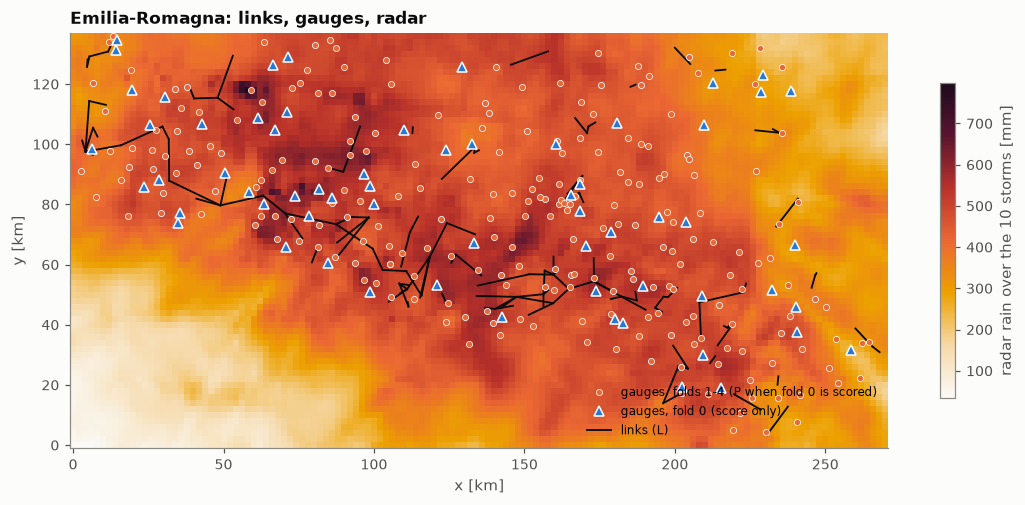

median distance from a gauge to the next gauge: 5.0 km


In [2]:
f = CACHE.parent / "ch13_radar_total.npy"
if not f.exists():
    np.save(f, sum(np.nansum(openrainer.Storm(e).radar(slice(None)), 0) for e in EVENTS))
tot = np.load(f)
ext = (-1, s.x[-1] + 1, -1, s.y[-1] + 1)
L, g = s.links, s.gauges
inside = g["inside"]
fig, ax = plt.subplots(figsize=(12, 6.2))
ax.grid(False)
im = ax.imshow(tot, origin="lower", cmap=viz.FIELD, extent=ext)
plt.colorbar(im, ax=ax, shrink=0.6, label="radar rain over the 10 storms [mm]")
for i in range(L["xa"].size):
    ax.plot([L["xa"][i], L["xb"][i]], [L["ya"][i], L["yb"][i]], color=viz.INK, lw=1.2)
ax.plot(g["x"][inside & (g["fold"] != 0)], g["y"][inside & (g["fold"] != 0)], "o", color=viz.ORANGE, ms=4,
        mec="white", mew=0.5, label="gauges, folds 1-4 (P when fold 0 is scored)")
ax.plot(g["x"][inside & (g["fold"] == 0)], g["y"][inside & (g["fold"] == 0)], "^", color=viz.BLUE, ms=7,
        mec="white", label="gauges, fold 0 (score only)")
ax.plot([], [], color=viz.INK, lw=1.2, label="links (L)")
ax.set(xlabel="x [km]", ylabel="y [km]", title="Emilia-Romagna: links, gauges, radar")
ax.legend(loc="lower right", fontsize=8)
viz.save(fig, "13_network.png")
plt.show()

gx, gy = g["x"][inside], g["y"][inside]
dg = np.hypot(gx[:, None] - gx, gy[:, None] - gy)
np.fill_diagonal(dg, np.inf)
print(f"median distance from a gauge to the next gauge: {np.median(dg.min(1)):.1f} km")

The opposite of Gothenburg in density. The 301 gauges inside the grid are about 5 km apart; the
130 links are short and scattered, a few per 10 km in the middle of the plain and almost none in the
hills to the south-west. A fifth of the gauges (blue) is held out at a time, so a held-out gauge
usually has an assimilated gauge 5 to 10 km away, and a link within 5 km a bit less than half the time.

## 2. The static maps
FieldSense's own maps, scored as it scores them. The table reproduces its ranking
(`projects/maps/multisensor/results/merging/ranking_openrainer_heldout_gauges.csv`) to the last digit.

In [3]:
t = openrainer.fieldsense_table()
C = t.common.values
OBS = t.obs.values


def score(e, sel=None):
    sel = C if sel is None else C & sel
    e, r = e[sel], OBS[sel]
    ok = np.isfinite(e) & np.isfinite(r)
    e, r = e[ok], r[ok]
    return dict(n=int(ok.sum()), nrmse=np.sqrt(np.mean((e - r) ** 2)) / r.mean(),
                corr=np.corrcoef(e, r)[0, 1], bias=e.sum() / r.sum() - 1)


STATIC = {"radar": "R", "links rnn line": "C (links, line IDW)", "gauges": "G (gauges, IDW)",
          "links rnn + gauges": "CG", "radar mfb [rnn]": "R adjusted by links (MFB)",
          "radar mfb [gauges]": "R adjusted by gauges (MFB)", "radar ked [gauges]": "KED: R + gauges",
          "radar ked [rnn + gauges]": "KED: R + links + gauges"}
table = {f"static {v}": score(t[k].values) for k, v in STATIC.items()}
print(pd.DataFrame(table).T.round(3).to_string())

                                         n  nrmse   corr   bias
static R                           97345.0  2.208  0.762  0.513
static C (links, line IDW)         68920.0  2.066  0.724  0.337
static G (gauges, IDW)             97345.0  1.580  0.838  0.006
static CG                          97345.0  1.595  0.835  0.102
static R adjusted by links (MFB)   97345.0  1.826  0.827  0.339
static R adjusted by gauges (MFB)  97345.0  1.528  0.845  0.014
static KED: R + gauges             97345.0  1.268  0.900  0.086
static KED: R + links + gauges     97345.0  1.420  0.876  0.182


The best map is the radar kriged on the gauges (KED, 1.27): the radar gives the pattern and the
gauges fix its level, which is 51 % too high. Gauges alone (1.58) are second-best family;
adding the links to KED makes it worse (1.42), and so does adding them to the gauge IDW (1.60).
The link map alone (2.07, only scored where it exists) is about as poor as the raw radar (2.21).

## 3. The twin, same settings as Gothenburg
One job per (mix, storm, fold) in `tools/italy_runs.py`. Each job keeps the twin at every gauge
cell; here the values are matched to FieldSense's rows, fold by fold.

In [4]:
def twin_column(mix, kind):
    out = np.full(len(t), np.nan)
    for ev in EVENTS:
        rows = np.flatnonzero(t.event.values == ev)
        for fold in (range(openrainer.FOLDS) if "P" in mix else [None]):
            d = np.load(CACHE / f"{mix}_{ev}_f{'all' if fold is None else fold}.npz")
            r = rows if fold is None else rows[t.fold.values[rows] == fold]
            si = pd.Index(d["station"]).get_indexer(t.station.values[r])
            ti = pd.Index(pd.DatetimeIndex(d["time"])).get_indexer(pd.DatetimeIndex(t.time.values[r]))
            out[r] = d[kind][ti, si]
    return out


TW = {(m, k): twin_column(m, k) for m in MIXES for k in ("mean", "now")}
for m in MIXES:
    table[f"twin {m} (mean)"] = score(TW[m, "mean"])
    table[f"twin {m} (now map)"] = score(TW[m, "now"])
T = pd.DataFrame(table).T
print(T.loc[[k for k in T.index if not (k.startswith("twin") and ("+" in k or "4km" in k))]].round(3).to_string())

                                         n  nrmse   corr   bias
static R                           97345.0  2.208  0.762  0.513
static C (links, line IDW)         68920.0  2.066  0.724  0.337
static G (gauges, IDW)             97345.0  1.580  0.838  0.006
static CG                          97345.0  1.595  0.835  0.102
static R adjusted by links (MFB)   97345.0  1.826  0.827  0.339
static R adjusted by gauges (MFB)  97345.0  1.528  0.845  0.014
static KED: R + gauges             97345.0  1.268  0.900  0.086
static KED: R + links + gauges     97345.0  1.420  0.876  0.182
twin L (mean)                      97345.0  3.415  0.329  0.067
twin L (now map)                   97345.0  2.611  0.451 -0.002
twin R (mean)                      97345.0  2.015  0.717  0.283
twin R (now map)                   97345.0  2.015  0.717  0.283
twin LR (mean)                     97345.0  2.451  0.726  0.685
twin LR (now map)                  97345.0  2.117  0.744  0.569
twin P (mean)                      97345

Out of the box, the twin is poor in Italy. Its best mix is the radar alone (2.02), barely better
than the raw radar and still 28 % high. Every mix that assimilates gauges or links is *worse* than
the radar-only twin: with gauges alone it is 35 % low (2.60), with everything 49 % high (2.12).
The radar-error twin, Chapter 10's best way to use the radar, ties the full twin (2.12). Nothing comes
near the gauge IDW (1.58), let alone KED.

## 4. Why the twin fails here
One storm, one fold, the gauge-only twin: what it believes at the gauges it assimilates, hour by hour.

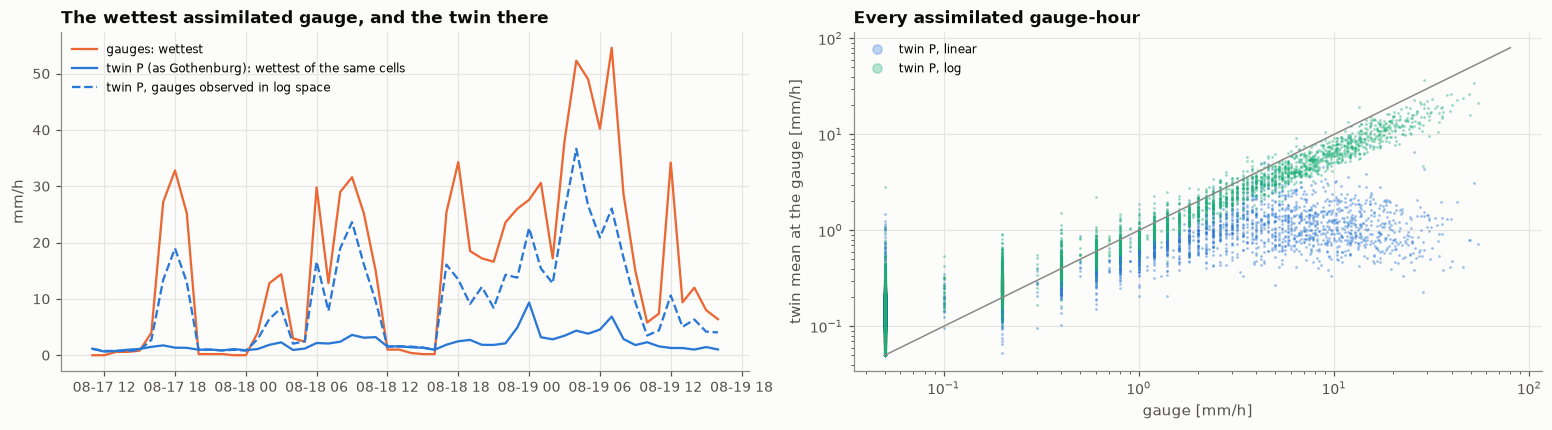

twin P, gauges linear: at its own gauges NRMSE 3.33, bias -70%
twin P, gauges log   : at its own gauges NRMSE 1.54, bias -21%


In [5]:
s0 = openrainer.Storm(FIG_EVENT, hold_out=0)
idx = np.arange(len(s0.times))
gu = s0.cells(s0.pws["x"], s0.pws["y"])
Gu = s0.pws_rain(idx)
trace = {}
for lab, kw in [("linear", {}), ("log", dict(point_log=True))]:
    o = system.run(s0, idx, "P", **kw)
    trace[lab] = o["mean"][:, gu[0], gu[1]]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
ax = axes[0]
ax.plot(s0.times, np.nanmax(Gu, 1), color=viz.DATA, lw=1.5, label="gauges: wettest")
ax.plot(s0.times, np.nanmax(trace["linear"], 1), color=viz.TWIN, lw=1.5, label="twin P (as Gothenburg): wettest of the same cells")
ax.plot(s0.times, np.nanmax(trace["log"], 1), color=viz.TWIN, lw=1.5, ls="--", label="twin P, gauges observed in log space")
ax.set(ylabel="mm/h", title="The wettest assimilated gauge, and the twin there")
ax.legend(fontsize=8)
ax = axes[1]
ok = np.isfinite(Gu)
for lab, ls in [("linear", "-"), ("log", "--")]:
    ax.loglog(np.clip(Gu[ok], 0.05, None), np.clip(trace[lab][ok], 0.05, None), ".", ms=2, alpha=0.3,
              color=viz.TWIN if ls == "-" else viz.AQUA, label=f"twin P, {lab}")
ax.plot([0.05, 80], [0.05, 80], color=viz.MUTED, lw=1)
ax.set(xlabel="gauge [mm/h]", ylabel="twin mean at the gauge [mm/h]", title="Every assimilated gauge-hour")
ax.legend(fontsize=8, markerscale=6)
viz.save(fig, "13_why.png")
plt.show()
for lab, M in trace.items():
    e, r = M[ok], Gu[ok]
    print(f"twin P, gauges {lab:6s}: at its own gauges NRMSE {np.sqrt(np.mean((e - r) ** 2)) / r.mean():.2f}, "
          f"bias {e.sum() / r.sum() - 1:+.0%}")

In [6]:
for m in ("LPR", "LPR+"):
    end = pd.Series({e: np.median(np.load(CACHE / f"{m}_{e}_f0.npz")["radar_factor"]) for e in EVENTS})
    print(f"twin {m:4s}: learned radar factor, median over the storm's hours: median {end.median():.2f} "
          f"(range {end.min():.2f} to {end.max():.2f})")
ratio = pd.Series({e: t.radar[C & (t.event.values == e)].sum() / OBS[C & (t.event.values == e)].sum() for e in EVENTS})
print(f"radar / gauges per storm: median {ratio.median():.2f} (range {ratio.min():.2f} to {ratio.max():.2f})")

twin LPR : learned radar factor, median over the storm's hours: median 0.84 (range 0.82 to 0.86)
twin LPR+: learned radar factor, median over the storm's hours: median 1.15 (range 0.99 to 1.47)
radar / gauges per storm: median 1.45 (range 0.83 to 3.16)


Three things go wrong, and each one is visible above.

**One update an hour cannot reach a shower.** In summer the wettest gauge reads 25 to 55 mm/h in
cells that appear and vanish within the hour. Between hours the twin's field relaxes towards
0.1 mm/h, so before each update it is nearly dry. The gauges are observed in mm/h, and a nearly dry
ensemble barely varies in mm/h, so the Kalman gain is tiny: the twin never rises above about 10 mm/h,
even at the gauges it assimilates (NRMSE 3.33 there, 70 % low; left panel, solid line). In Gothenburg
the same twin got twelve updates an hour and could climb step by step. Observing the gauges in
log space, as the radar already is, makes the update linear in the state and lets one update move
the field by as much as it needs (dashed line, NRMSE 1.54 at its own gauges).

**The radar's bias never moves.** The twin estimates the radar's log-bias as part of its state, but
the bias has no process noise. After the first update, with about 1000 radar cells, its ensemble
spread collapses and it stays where it landed: 0.82 to 0.86 in every storm, i.e. "the radar reads
low", while the radar is 1.45 times the gauges in the median storm. This is a bug in the twin, not
a property of Italy, and it was there in Chapters 10 and 12 as well. A small random walk on the bias
(`q_bias=0.02` per 5 min, like the one on the velocity) lets it learn: 1.0 to 1.5, median 1.15.

**An hour is too long for the twin's motion.** The twin's value in Gothenburg came from carrying
the field from one 5-min step to the next. Summer showers grow, move and die within the hour, so
last hour's field says little about this hour's: the forecast step
adds almost nothing, and the twin is left as an interpolator. As an interpolator it is worse than
IDW: its corrections spread with a 6 km noise scale and a 15 km localisation, and between gauges they
fall back to a nearly dry background, where IDW copies the nearest gauge.

## 5. Two fixes, and the cost of the coarse radar

In [7]:
rows = ["static R", "static G (gauges, IDW)", "static KED: R + gauges", "twin R (mean)", "twin R-4km (mean)",
        "twin P (now map)", "twin P+ (now map)", "twin LPR (now map)", "twin LPR+ (now map)", "twin E-LP (now map)"]
print(T.loc[rows].round(3).to_string())

                              n  nrmse   corr   bias
static R                97345.0  2.208  0.762  0.513
static G (gauges, IDW)  97345.0  1.580  0.838  0.006
static KED: R + gauges  97345.0  1.268  0.900  0.086
twin R (mean)           97345.0  2.015  0.717  0.283
twin R-4km (mean)       97345.0  1.995  0.750  0.416
twin P (now map)        97345.0  2.597  0.438 -0.346
twin P+ (now map)       97345.0  2.301  0.626 -0.198
twin LPR (now map)      97345.0  2.120  0.746  0.490
twin LPR+ (now map)     97345.0  1.935  0.745  0.105
twin E-LP (now map)     97345.0  2.119  0.770  0.390


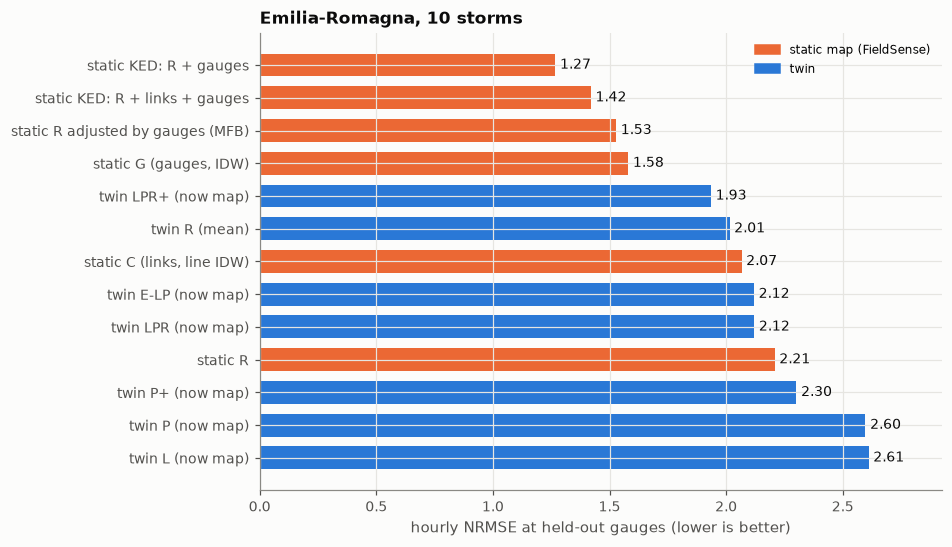

In [8]:
show = ["static R", "static C (links, line IDW)", "static G (gauges, IDW)", "static R adjusted by gauges (MFB)",
        "static KED: R + links + gauges", "static KED: R + gauges", "twin L (now map)", "twin R (mean)",
        "twin P (now map)", "twin LPR (now map)", "twin E-LP (now map)", "twin P+ (now map)", "twin LPR+ (now map)"]
order = T.loc[show].sort_values("nrmse")
cols = [viz.ORANGE if "static" in k else viz.TWIN for k in order.index]
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(range(len(order)), order.nrmse, color=cols, height=0.7)
ax.set_yticks(range(len(order)), order.index)
ax.invert_yaxis()
for i, v in enumerate(order.nrmse):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=9, color=viz.INK)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=viz.ORANGE), plt.Rectangle((0, 0), 1, 1, color=viz.TWIN)],
          labels=["static map (FieldSense)", "twin"], loc="upper right", fontsize=8)
ax.set(xlim=(0, order.nrmse.max() * 1.12), xlabel="hourly NRMSE at held-out gauges (lower is better)",
       title="Emilia-Romagna, 10 storms")
viz.save(fig, "13_scores.png")
plt.show()

With both fixes (`P+`, `LPR+`: gauges in log space, radar bias with a random walk) the full twin
improves from 2.12 to 1.93 and its bias from +49 % to +10 %; the gauge-only twin from 2.60 to 2.30.
That makes the full twin the best twin and better than the raw radar, but it is still behind the
gauge IDW (1.58) and far behind KED (1.27).

The coarse radar (every 6 km instead of 4 km) is not the reason: the radar-only twin with the
Gothenburg spacing scores 2.00 against 2.02. (On the storm of section 4 alone the difference looked
larger, 1.92 against 2.21; over all 10 storms it is 0.02.)

## 6. Near the links and far from them, storm by storm

In [9]:
near = t.km_to_link.values <= 5
rows = {}
for lab, col in [("static C (links)", t["links rnn line"].values), ("static G (gauges)", t["gauges"].values),
                 ("static KED: R + gauges", t["radar ked [gauges]"].values),
                 ("static KED: R + links + gauges", t["radar ked [rnn + gauges]"].values),
                 ("twin P+ (now map)", TW["P+", "now"]), ("twin LPR (now map)", TW["LPR", "now"]),
                 ("twin LPR+ (now map)", TW["LPR+", "now"])]:
    rows[lab] = {"<= 5 km of a link": score(col, near)["nrmse"], "> 5 km": score(col, ~near)["nrmse"]}
print(f"gauge-hours: {(C & near).sum()} within 5 km of a link, {(C & ~near).sum()} further")
print(pd.DataFrame(rows).T.round(3).to_string())

per = {}
for e in EVENTS:
    sel = t.event.values == e
    per[e] = {"radar": score(t.radar.values, sel)["nrmse"], "gauges IDW": score(t["gauges"].values, sel)["nrmse"],
              "KED R+G": score(t["radar ked [gauges]"].values, sel)["nrmse"],
              "twin LPR+": score(TW["LPR+", "now"], sel)["nrmse"]}
PS = pd.DataFrame(per).T
print(PS.round(2).to_string())
d = PS["twin LPR+"] - PS["KED R+G"]
rng = np.random.default_rng(0)
boot = np.array([d.values[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)])
print(f"twin LPR+ - KED, mean over storms: {d.mean():+.3f} (95 % interval {np.percentile(boot, 2.5):+.3f} "
      f"to {np.percentile(boot, 97.5):+.3f}); twin better in {(d < 0).sum()} of {len(d)} storms")
d = PS["twin LPR+"] - PS["radar"]
print(f"twin LPR+ - radar: {d.mean():+.3f}; twin better in {(d < 0).sum()} of {len(d)} storms")

gauge-hours: 42941 within 5 km of a link, 54404 further
                                <= 5 km of a link  > 5 km
static C (links)                            1.942   2.244
static G (gauges)                           1.431   1.698
static KED: R + gauges                      1.202   1.321
static KED: R + links + gauges              1.409   1.428
twin P+ (now map)                           2.085   2.472
twin LPR (now map)                          2.152   2.092
twin LPR+ (now map)                         1.917   1.949
             radar  gauges IDW  KED R+G  twin LPR+
20210523T23   1.17        0.60     0.53       1.14
20210926T06   1.09        0.92     0.74       1.25
20211005T19   2.19        1.60     1.40       1.86
20211113T11   1.96        0.99     0.86       1.27
20220505T09   1.42        0.61     0.63       0.88
20220806T09   9.00        6.16     5.06       6.52
20220817T10   1.76        1.79     1.26       2.14
20220830T11   4.07        3.92     3.25       3.56
20220929T10   4.46   

twin LPR+ - KED, mean over storms: +0.648 (95 % interval +0.440 to +0.911); twin better in 0 of 10 storms
twin LPR+ - radar: -0.679; twin better in 8 of 10 storms


The links do not help the twin even where they are: within 5 km of a link the fixed twin scores
1.92, further away 1.95. KED, which uses no links, is better on both sides (1.20 and 1.32).

Storm by storm, the fixed twin beats the raw radar in 8 of 10 storms and the gauge IDW in one
(30 August). It never beats KED: on average it is 0.65 worse (95 % interval over storms 0.44 to
0.91). Two storms, 6 August and 30 August, have NRMSE above 3 for every map: they are the two
driest (0.21 and 0.37 mm/h at the gauges), and a few local showers dominate their error.

## 7. One storm in the twin

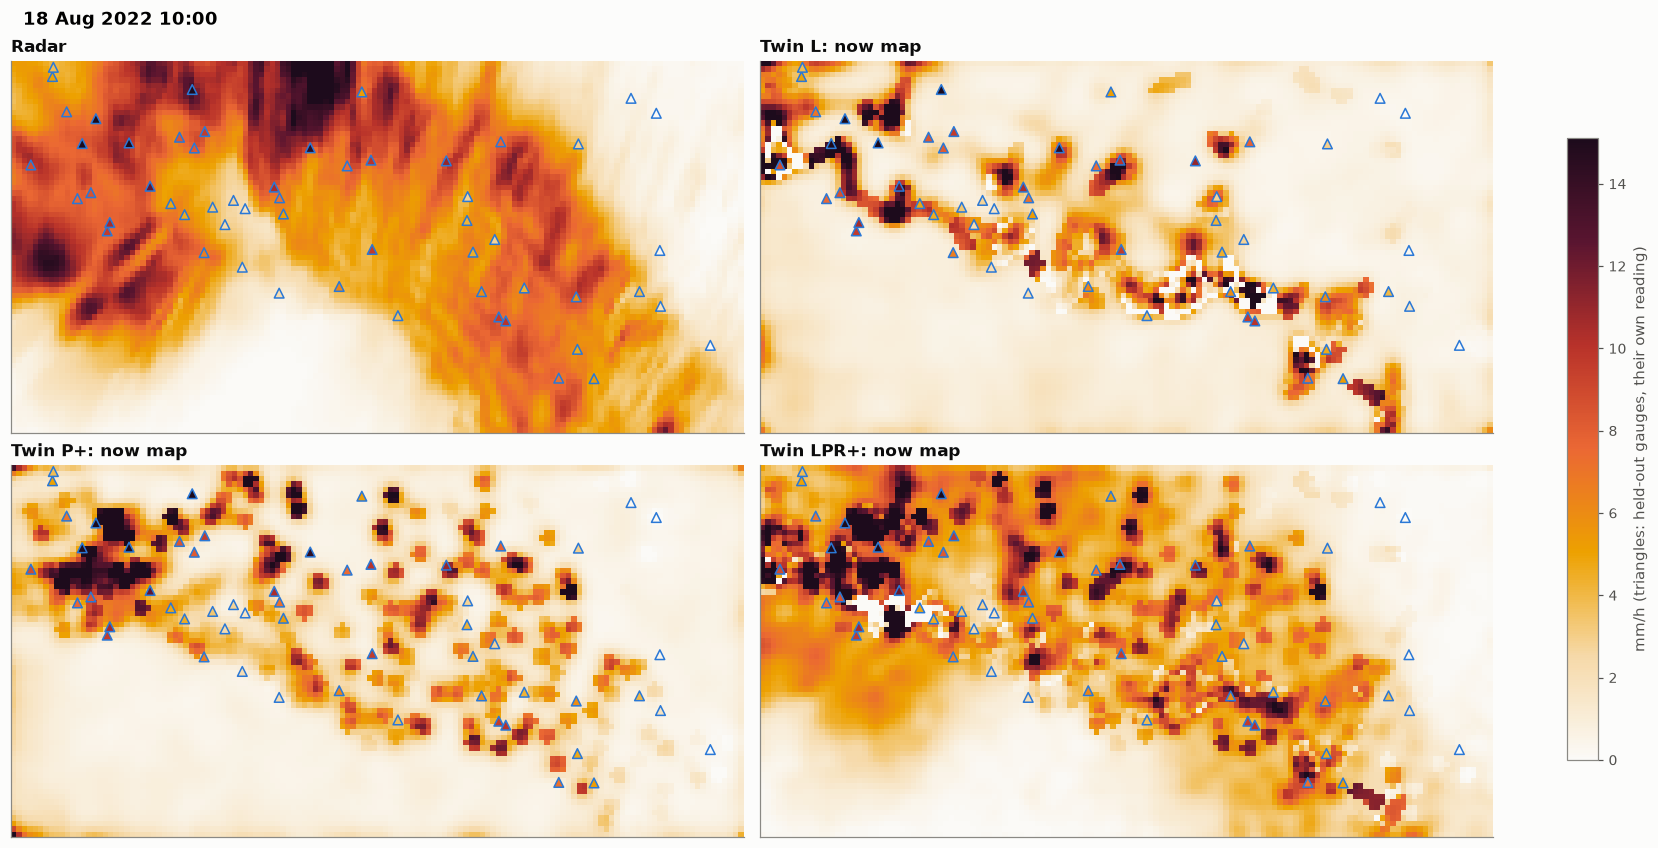

In [10]:
d0 = np.load(CACHE / f"LPR+_{FIG_EVENT}_f0.npz")
dP = np.load(CACHE / f"P+_{FIG_EVENT}_f0.npz")
dL = np.load(CACHE / f"L_{FIG_EVENT}_fall.npz")
k = int(np.nanargmax(np.nanmean(s.radar(slice(None)), (1, 2))))
fields = [(np.nan_to_num(s.radar([k])[0]), "Radar"), (dL["map_now"][k], "Twin L: now map"),
          (dP["map_now"][k], "Twin P+: now map"), (d0["map_now"][k], "Twin LPR+: now map")]
vm = np.nanpercentile(fields[0][0], 99.5)
gk = s.gauge_rain([k])[0]
held = inside & (g["fold"] == 0)
fig, axes = plt.subplots(2, 2, figsize=(15, 7.6), constrained_layout=True)
for ax, (F, ttl) in zip(axes.ravel(), fields):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=viz.FIELD, vmin=0, vmax=vm, extent=ext)
    ax.scatter(g["x"][held], g["y"][held], c=gk[held], cmap=viz.FIELD, vmin=0, vmax=vm, marker="^", s=40,
               edgecolors=viz.BLUE, linewidths=1)
    ax.set(title=ttl, xticks=[], yticks=[])
plt.colorbar(im, ax=axes, shrink=0.8, label="mm/h (triangles: held-out gauges, their own reading)")
fig.suptitle(f"{s.times[k]:%d %b %Y %H:%M}", x=0.01, ha="left", fontweight="bold")
viz.save(fig, "13_maps.png")
plt.show()

The radar shows a wide band of rain with embedded cells. The links-only twin has rain only along
the links, with white speckle where the now map's correction is negative and is clipped to zero.
The gauge-only twin is a field of gauge-sized blobs: in log space each gauge pulls its own few cells
to its value, and between gauges the field falls back towards the dry background. With the radar
the band comes back, but with the same blobs on top.

## Conclusions
* The twin built on Gothenburg's 5-minute data does not transfer to hourly data with a dense gauge
  network. Untuned, its best map (radar only, 2.02) barely beats the raw radar (2.21); adding gauges
  or links makes it worse. FieldSense's KED (1.27) and even the gauge IDW (1.58) are far better.
* Two of the three causes are fixable and were fixed here: point sensors should be observed in log
  space when the twin may be far from them (one update must cover a shower), and a sensor's bias
  needs a random walk, or it freezes at its first estimate. Fixed, the full twin reaches 1.93 with
  a +10 % bias: the best twin, still well behind KED in every storm.
* The third cause is the data. A twin earns its keep by carrying the field through time; at one
  step an hour, summer showers do not survive from one step to the next, and the twin is an
  interpolator with a worse spatial model than kriging. Where the time step is long compared with
  the life of a rain cell, a static merge is the right tool.
* The links add nothing in Emilia-Romagna, to the twin or to FieldSense's merges, with 300 gauges
  5 km apart. This matches FieldSense's finding for this network.
* The frozen radar bias is in Chapters 10 and 12 as well, so their "learned radar bias" was the
  first update's estimate. Their section 6 reruns them with both fixes: in Gothenburg the now
  map does not change (1.06), and in New York the unfrozen bias runs off and the twin gets
  worse (0.58 to 0.84). The random walk helps only where other sensors pin the rain level, as
  300 gauges do here.